In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
 

In [6]:
df=pd.read_csv("carprices.csv")

In [7]:
df

,Car Model,Mileage,Sell Price($),Age(yrs)
0,BMW X5,69000,18000,6
1,BMW X5,35000,34000,3
2,BMW X5,57000,26100,5
3,BMW X5,22500,40000,2
4,BMW X5,46000,31500,4
5,Audi A5,59000,29400,5
6,Audi A5,52000,32000,5
7,Audi A5,72000,19300,6
8,Audi A5,91000,12000,8
9,Mercedez Benz C class,67000,22000,6


In [9]:
df.head()

,Car Model,Mileage,Sell Price($),Age(yrs)
0,BMW X5,69000,18000,6
1,BMW X5,35000,34000,3
2,BMW X5,57000,26100,5
3,BMW X5,22500,40000,2
4,BMW X5,46000,31500,4


In [10]:
df.tail()

,Car Model,Mileage,Sell Price($),Age(yrs)
8,Audi A5,91000,12000,8
9,Mercedez Benz C class,67000,22000,6
10,Mercedez Benz C class,83000,20000,7
11,Mercedez Benz C class,79000,21000,7
12,Mercedez Benz C class,59000,33000,5


In [11]:
df.shape

(13, 4)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Car Model      13 non-null     str  
 1   Mileage        13 non-null     int64
 2   Sell Price($)  13 non-null     int64
 3   Age(yrs)       13 non-null     int64
dtypes: int64(3), str(1)
memory usage: 548.0 bytes


In [14]:
df.describe()

,Mileage,Sell Price($),Age(yrs)
count,13.000000,13.000000,13.000000
mean,60884.615385,26023.076923,5.307692
std,19185.665055,8003.661021,1.652504
min,22500.000000,12000.000000,2.000000
25%,52000.000000,20000.000000,5.000000
50%,59000.000000,26100.000000,5.000000
75%,72000.000000,32000.000000,6.000000
max,91000.000000,40000.000000,8.000000


In [16]:
col_num=['Mileage','Age(yrs)']

In [20]:
from scipy.stats import skew

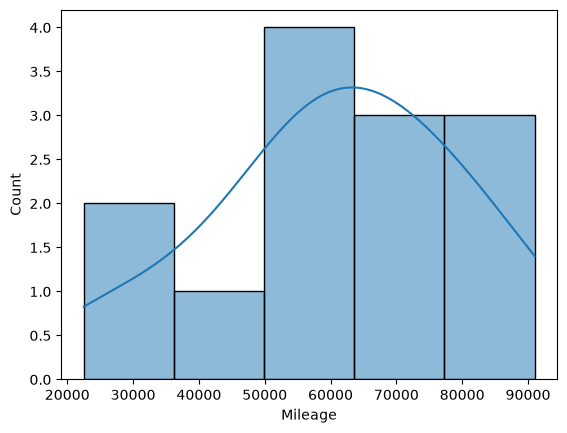

-0.3900594574431897


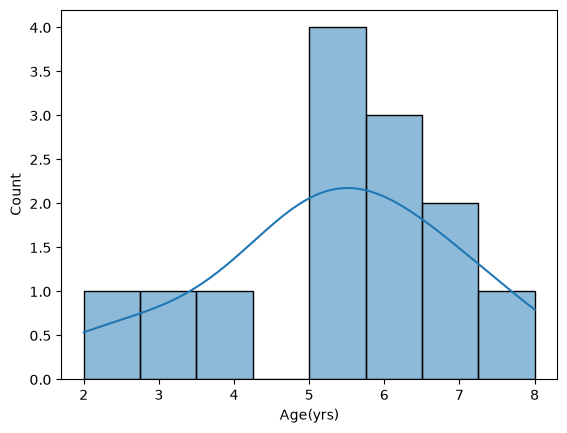

-0.39647242223631923


In [21]:
for col in col_num:
    plt.figure()
    sns.histplot(df[col],kde=True)
    plt.show()
    print(skew(df[col]))

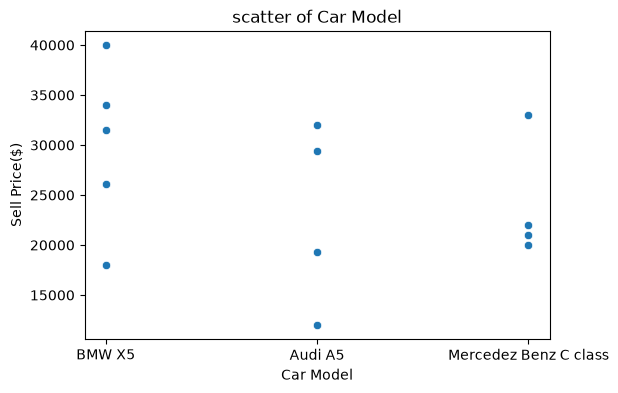

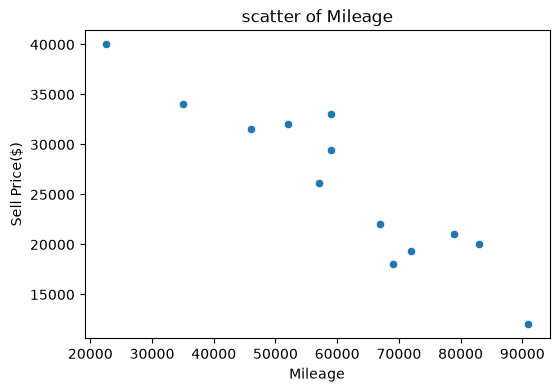

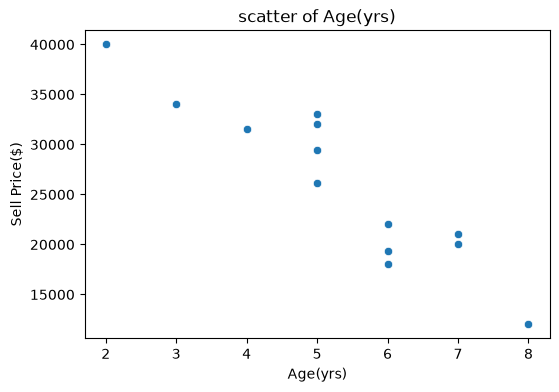

In [26]:
columns = ["Car Model","Mileage","Age(yrs)"]

for col in columns:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[col],y=df['Sell Price($)'])
    plt.title(f"scatter of {col}")
    plt.show()

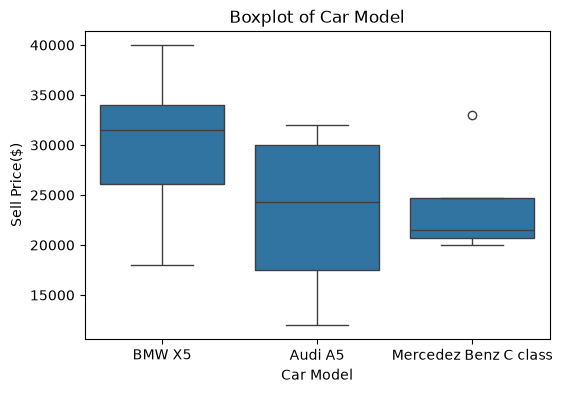

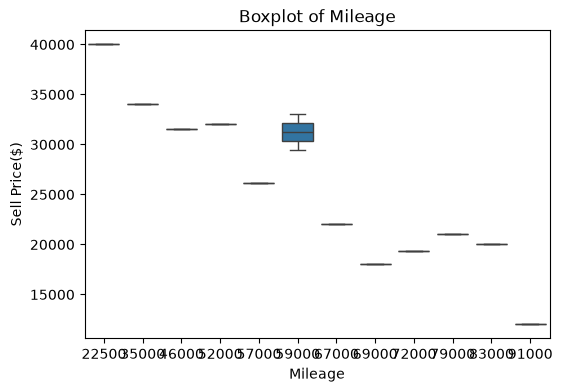

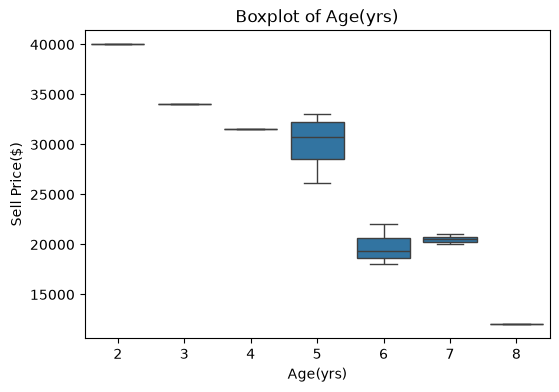

In [27]:
columns = ["Car Model","Mileage","Age(yrs)"]

for col in columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col],y=df['Sell Price($)'])
    plt.title(f"Boxplot of {col}")
    plt.show()

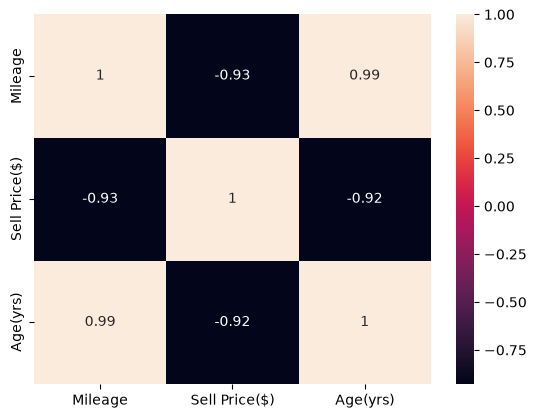

In [31]:
X=df[["Mileage","Sell Price($)",'Age(yrs)']]

plt.figure()
sns.heatmap(X.corr(),annot=True)
plt.show()

In [33]:
#  one hot encoding

In [34]:
car_moel_col=pd.get_dummies(df['Car Model'],dtype='int')

In [35]:
df_new=pd.concat([df,car_moel_col],axis=1)
df_new.drop('Car Model',axis=1,inplace=True)

In [36]:
df_new.head()

,Mileage,Sell Price($),Age(yrs),Audi A5,BMW X5,Mercedez Benz C class
0,69000,18000,6,0,1,0
1,35000,34000,3,0,1,0
2,57000,26100,5,0,1,0
3,22500,40000,2,0,1,0
4,46000,31500,4,0,1,0


In [37]:
df_new.tail()

,Mileage,Sell Price($),Age(yrs),Audi A5,BMW X5,Mercedez Benz C class
8,91000,12000,8,1,0,0
9,67000,22000,6,0,0,1
10,83000,20000,7,0,0,1
11,79000,21000,7,0,0,1
12,59000,33000,5,0,0,1


In [38]:
# separate x and y

In [57]:
 # 3. Separate Independent (X) and Dependent (y) variables
X = df_new.drop(columns=['Sell Price($)'])
y = df_new['Sell Price($)']

In [73]:
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.linear_model import LinearRegression

In [83]:
 
model = RandomForestRegressor(n_estimators=150)

In [84]:
cv=cross_val_score(
    model,
    X,y,cv=4,
    scoring="r2"
)

In [85]:
cv

array([ 0.59119135, -4.05092493, -0.44887892,  0.71190848])

In [86]:
print(cv.mean())

-0.7991760059898999
